# Kiosk sessions

This is a payment-operations log for self-serve kiosks. Tenants run stores. Stores run kiosks. A guest or customer walks up to a kiosk, starts a session, and moves through the order steps. Some stores take more steps (or more time) to finish than others. The start of the path is the session. The end of a completed path is a purchase.

Start with the discovery queries: inventory, grain, session check, store list. Charts after that answer whatever those tables leave hanging. Outputs were saved from the repo root.


In [1]:
%matplotlib inline
import html
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "sql" / "init_ddl.sql").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

con = duckdb.connect()
con.execute((ROOT / "data" / "sql" / "init_ddl.sql").read_text())

TITLE = 14
POINT = 8
PANEL = "#EAEAF2"
plt.rcParams.update(
    {
        "figure.facecolor": PANEL,
        "savefig.facecolor": PANEL,
        "axes.facecolor": PANEL,
        "axes.edgecolor": "white",
        "axes.labelcolor": "#1B2838",
        "axes.titlecolor": "#1B2838",
        "text.color": "#1B2838",
        "xtick.color": "#3C3C4A",
        "ytick.color": "#3C3C4A",
        "axes.prop_cycle": plt.cycler(color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"]),
    }
)

LEGEND = dict(
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#D5D5E2",
    framealpha=0.95,
    borderpad=0.4,
    labelspacing=0.35,
    handlelength=1.6,
    handletextpad=0.5,
)


def tenant_name(value):
    return str(value).replace("tenant_", "Tenant ")


def short_num(value):
    value = float(value)
    if abs(value) >= 1000:
        return f"{value / 1000:.1f}k"
    return f"{value:.0f}"


def polish(ax, title, xlabel=None, ylabel=None, grid="both"):
    ax.figure.set_facecolor(PANEL)
    ax.set_facecolor(PANEL)
    ax.set_title(title, fontsize=TITLE, pad=12, color="#1B2838")
    ax.tick_params(labelsize=8, colors="#3C3C4A")
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9, color="#1B2838")
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9, color="#1B2838")
    for spine in ax.spines.values():
        spine.set_color("white")
        spine.set_linewidth(1)
    ax.set_axisbelow(True)
    ax.grid(False)
    if grid in ("y", "both"):
        ax.yaxis.grid(True, color="white", linewidth=1)
    if grid in ("x", "both"):
        ax.xaxis.grid(True, color="white", linewidth=1)


def point(ax, x, y, text, color="#1B2838", xytext=(0, 2), va="bottom", ha="center", bbox=None):
    ax.annotate(
        text,
        (x, y),
        textcoords="offset points",
        xytext=xytext,
        ha=ha,
        va=va,
        fontsize=POINT,
        color=color,
        bbox=bbox,
    )


pd.set_option("display.colheader_justify", "left")


class LeftTable(pd.DataFrame):
    def _repr_html_(self):
        head = "".join(
            f'<th style="text-align:left">{html.escape(str(col))}</th>' for col in self.columns
        )
        body = []
        for idx, row in self.iterrows():
            cells = "".join(
                f'<td style="text-align:left">{html.escape(str(value))}</td>' for value in row
            )
            body.append(
                f'<tr><th style="text-align:left">{html.escape(str(idx))}</th>{cells}</tr>'
            )
        return (
            '<table class="dataframe">'
            f'<thead><tr><th style="text-align:left"></th>{head}</tr></thead>'
            f"<tbody>{''.join(body)}</tbody></table>"
        )


def show_tenants(frame):
    out = frame.copy()
    if "tenant" in out.columns:
        out["tenant"] = out["tenant"].map(tenant_name)
    return out


def present(frame):
    out = show_tenants(frame)
    shown = pd.DataFrame(index=out.index)
    for col in out.columns:
        series = out[col]
        name = str(col).lower()
        money = "revenue" in name and "count" not in name and not name.startswith("unique_")
        if money:
            numeric = pd.to_numeric(series, errors="coerce")
            if int(numeric.notna().sum()) == int(series.notna().sum()):
                shown[col] = [
                    "" if pd.isna(value) else f"{float(value):.1f}" for value in numeric
                ]
                continue
        if pd.api.types.is_datetime64_any_dtype(series):
            shown[col] = series.dt.strftime("%Y-%m-%dT%H:%M:%S")
        else:
            shown[col] = ["" if pd.isna(value) else str(value) for value in series]
    return LeftTable(shown)


def sql_file(path):
    raw = (ROOT / path).read_text()
    raw = re.sub(r"/\*.*?\*/", "", raw, flags=re.S)
    frames = []
    for chunk in raw.split(";"):
        kept = [line for line in chunk.splitlines() if not line.strip().startswith("--")]
        statement = "\n".join(kept).strip()
        if statement:
            frames.append(present(con.sql(statement).df()))
    return frames


def load_identity():
    global identity, file_counts
    if "identity" not in globals():
        identity = con.sql("""
        SELECT
            session_id,
            MIN(tenant) AS tenant,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            COUNT(DISTINCT tenant) AS tenants,
            COUNT(DISTINCT store_id_unified) AS stores,
            COUNT(DISTINCT kiosk_id_up) AS kiosks,
            COUNT(DISTINCT event_date) AS dates,
            MIN(event_date) AS first_date,
            MAX(event_date) AS last_date
        FROM events
        GROUP BY session_id
        """).df()
    if "file_counts" not in globals():
        file_counts = con.sql("""
        SELECT
            COUNT(*) AS rows,
            COUNT(*) - COUNT(DISTINCT session_id || '|' || CAST(event_index AS VARCHAR)) AS duplicate_pairs
        FROM events
        """).df()
    return identity, file_counts


def load_daily():
    global daily
    if "daily" not in globals():
        daily = con.sql("""
        SELECT
            event_date,
            tenant,
            COUNT(DISTINCT session_id) AS unique_sessions,
            SUM(item_revenue) AS total_item_revenue
        FROM events
        GROUP BY event_date, tenant
        ORDER BY event_date, tenant
        """).df()
    return daily


def load_session_flags():
    global session_flags
    if "session_flags" not in globals():
        session_flags = con.sql("""
        SELECT
            tenant,
            session_id,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            MAX(event_name = 'view_item_list') AS viewed,
            MAX(event_name = 'select_item') AS selected,
            MAX(event_name = 'add_to_cart') AS carted,
            MAX(event_name = 'purchase') AS purchased,
            COUNT(*) FILTER (WHERE event_name = 'purchase') AS purchase_rows,
            COALESCE(SUM(item_revenue) FILTER (WHERE event_name = 'purchase'), 0) AS purchase_revenue
        FROM events
        GROUP BY tenant, session_id
        """).df()
    return session_flags


## What is in the file

`data/sql/discovery_query.sql`. First table is the whole file. Second repeats the counts by tenant. Revenue sum mixes price units, so do not treat it as a ranking. Later charts stay off that sum.


In [2]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_query.sql"):
    display(frame)


,row_count,unique_tenants_count,unique_sessions_count,unique_event_names_count,unique_event_indexes_count,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum
0,1814373,2,36693,4,353,31,64,596,46176,1142573.6


,tenant,rows,sessions,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum,min_date,max_date
0,Tenant 1,1648005,32291,29,58,317,40936,440528.6,2026-04-17T00:00:00,2026-05-01T00:00:00
1,Tenant 2,166368,4402,2,6,279,5240,702045.0,2026-04-17T00:00:00,2026-05-01T00:00:00


## Whether a session stays in one place

`data/sql/discovery_grain.sql`. One row is one event. First table: `session_id` + `event_index` repeats 46 times. Second table: does one session cross a tenant, store, kiosk, or date? No on tenant / store / kiosk. Nine sessions touch two dates.


In [3]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_grain.sql"):
    display(frame)


,row_count,distinct_session_event_index,duplicate_pairs
0,1814373,1814327,46


,check_name,sessions_with_multiple
0,tenants_per_session,0
1,stores_per_session,0
2,kiosks_per_session,0
3,dates_per_session,9


## A session is one visit

`data/sql/discovery_session_identity.sql`. Nine sessions hit more than one date; longest span is one day. No guest id, so a session is a visit, not a returning customer. Daily table below feeds the next chart. Its revenue column still is not a cross-tenant ranking.


In [4]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_session_identity.sql"):
    display(frame)


,sessions,sessions_spanning_multiple_dates,max_day_span
0,36693,9,1


,event_date,tenant,event_rows,unique_sessions,unique_item_revenues,total_item_revenue
0,2026-04-17T00:00:00,Tenant 1,147284,2940,308,40553.9
1,2026-04-17T00:00:00,Tenant 2,13848,375,60,61182.0
2,2026-04-18T00:00:00,Tenant 1,132150,2518,337,37408.1
3,2026-04-18T00:00:00,Tenant 2,9562,242,62,39802.0
4,2026-04-19T00:00:00,Tenant 1,107556,2076,283,29822.5
5,2026-04-19T00:00:00,Tenant 2,10965,282,61,55412.0
6,2026-04-20T00:00:00,Tenant 1,97161,1891,251,23542.4
7,2026-04-20T00:00:00,Tenant 2,12152,309,58,53920.0
8,2026-04-21T00:00:00,Tenant 1,99520,1954,269,24653.0
9,2026-04-21T00:00:00,Tenant 2,10577,289,61,33913.0


## Stores, kiosks, and raw revenue

`data/sql/discovery_kiosk_stores.sql`. One row per kiosk, then one per store. Raw revenue puts Tenant 2's stores first because the price unit differs. Last result is kiosks that sit in more than one store. Empty table means that count is zero.


In [5]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_kiosk_stores.sql"):
    display(frame)
    if frame.empty:
        print("0 rows. No kiosk sits in more than one store.")


,tenant,store_id_unified,kiosk_id_up
0,Tenant 1,11330,19685
1,Tenant 1,11330,19686
2,Tenant 1,11478,19625
3,Tenant 1,11478,19626
4,Tenant 1,11598,19543
5,Tenant 1,11598,19544
6,Tenant 1,11599,19598
7,Tenant 1,11599,19599
8,Tenant 1,12321,24356
9,Tenant 1,12321,24357


,tenant,store_id_unified,kiosk_id_up_count,avg_item_revenue,total_item_revenue
0,Tenant 1,2516,3,9.6,37215.5
1,Tenant 1,14343,2,10.3,36402.0
2,Tenant 1,15644,3,10.8,29249.3
3,Tenant 1,16053,2,9.6,23751.7
4,Tenant 1,15866,2,11.7,23471.9
5,Tenant 1,15109,2,10.3,22090.5
6,Tenant 1,15445,2,10.6,20636.6
7,Tenant 1,15682,2,10.9,19480.3
8,Tenant 1,15348,2,11.9,18299.1
9,Tenant 1,11598,2,10.1,17443.9


,kiosk_id_up_count


0 rows. No kiosk sits in more than one store.


## Where a visit sits

Tenant owns stores. Store owns kiosks. A session lives on one kiosk. Tenant 1 has 29 stores, so this diagram only shows two (one with two kiosks, one with three). Tenant 2 shows both stores.

![Tenant, store, and kiosk sample](../docs/gallery/where-a-visit-sits.png)

```mermaid
flowchart TD
  subgraph t1["Tenant 1"]
    s15866["Store 15866"] --> k28016["Kiosk 28016"]
    s15866 --> k28017["Kiosk 28017"]
    s2516["Store 2516"] --> k30290["Kiosk 30290"]
    s2516 --> k30291["Kiosk 30291"]
    s2516 --> k30292["Kiosk 30292"]
  end
  subgraph t2["Tenant 2"]
    s227["Store 227"] --> k29834["Kiosk 29834"]
    s227 --> k29835["Kiosk 29835"]
    s278["Store 278"] --> k29837["Kiosk 29837"]
    s278 --> k29838["Kiosk 29838"]
    s278 --> k29839["Kiosk 29839"]
    s278 --> k29840["Kiosk 29840"]
  end
```


## The path a session is built to follow

Intended path on the kiosk. Later charts still count a step if that event shows up at least once, even when the guest skipped around.

![Session journey](../docs/gallery/session-journey.png)

```mermaid
flowchart LR
  session["Session"] --> view["View item list"]
  view --> select["Select item"]
  select --> cart["Add to cart"]
  cart --> purchase["Purchase"]
```


## The gap holds on every day

Tenant table already says Tenant 1 has way more sessions. This chart checks whether that holds every day, or only on a few busy ones.


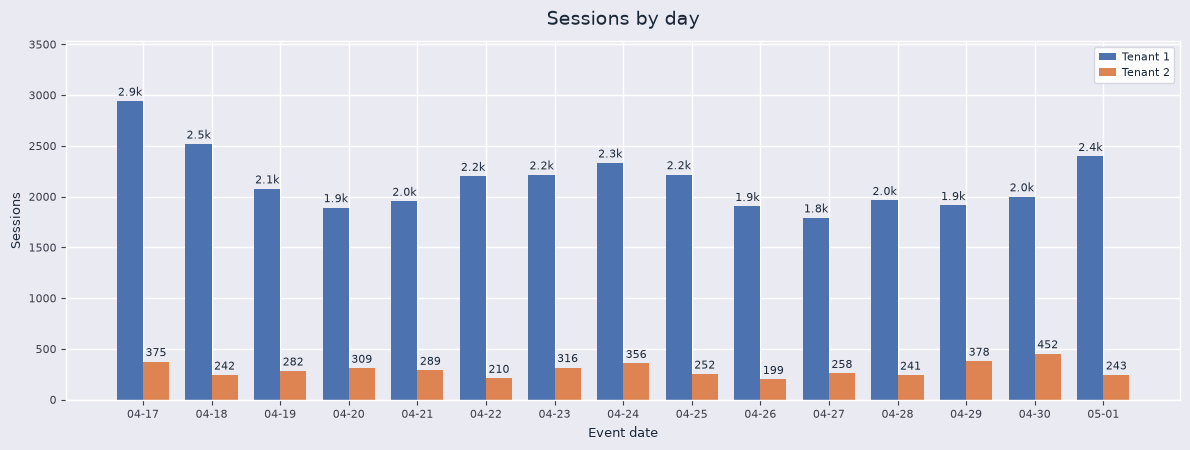

In [6]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
dates = list(frame["day"].drop_duplicates().sort_values())
tenants = sorted(frame["tenant"].unique())
x = np.arange(len(dates))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.6))
peak = 0
series = []
for tenant in tenants:
    values = (
        frame.loc[frame["tenant"] == tenant]
        .set_index("day")
        .reindex(dates)["unique_sessions"]
        .fillna(0)
        .to_numpy(dtype=float)
    )
    series.append(values)
    peak = max(peak, float(values.max()))
for i, (tenant, values) in enumerate(zip(tenants, series)):
    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=tenant_name(tenant),
        color=f"C{i}",
    )
    other = series[1 - i] if len(series) == 2 else None
    for j, (bar, value) in enumerate(zip(bars, values)):
        close = other is not None and abs(value - other[j]) < peak * 0.06
        point(
            ax,
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            short_num(value),
            xytext=(0, 9 if close and i else 2),
        )
ax.set_xticks(x)
ax.set_xticklabels([day.strftime("%m-%d") for day in dates])
ax.set_ylim(0, peak * 1.2)
polish(ax, "Sessions by day", xlabel="Event date", ylabel="Sessions")
ax.legend(loc="upper right", **LEGEND)
fig.tight_layout()
plt.show()


## Most visits reach a purchase

A session counts at a step if that event shows up at least once. Top line is the step. Bottom line is count | share of all sessions. Those labels are the true shares. Drawing uses an even taper unless `PROPORTIONAL` is on, so band widths are not the shares. Set `PROPORTIONAL = True` to size bands from the session counts. That taper stays shallow because most sessions still purchase.


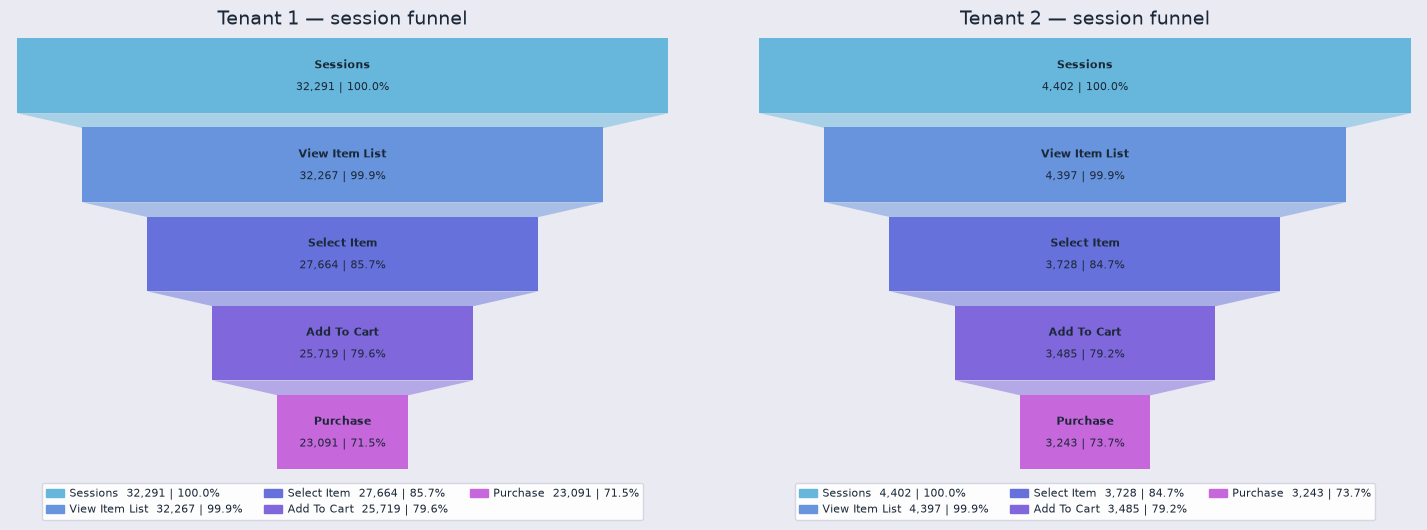

In [7]:
from matplotlib.patches import Patch

session_flags = load_session_flags()
funnel = (
    session_flags.groupby("tenant", as_index=False)
    .agg(
        sessions=("session_id", "size"),
        viewed=("viewed", "sum"),
        selected=("selected", "sum"),
        carted=("carted", "sum"),
        purchased=("purchased", "sum"),
    )
    .sort_values("tenant")
)

stages = ["sessions", "view_item_list", "select_item", "add_to_cart", "purchase"]
columns = ["sessions", "viewed", "selected", "carted", "purchased"]
colors = ["#67B7DC", "#6794DC", "#6771DC", "#8067DC", "#C767DC"]
# False keeps an even taper. True uses the session counts, and the taper stays shallow.
PROPORTIONAL = False


def draw_funnel(ax, labels, values):
    n = len(values)
    if PROPORTIONAL:
        half = [value / values[0] for value in values]
    else:
        half = [1 - i * (0.8 / (n - 1)) for i in range(n)]
    body, neck = 1.0, 0.2
    y = n * body + (n - 1) * neck
    handles = []
    for i, (label, value, color) in enumerate(zip(labels, values, colors)):
        share = 100 * value / values[0]
        y_top = y
        y_body = y_top - body
        ax.fill_betweenx([y_body, y_top], -half[i], half[i], color=color, linewidth=0)
        if i < n - 1:
            y_bot = y_body - neck
            ax.fill_betweenx(
                [y_bot, y_body],
                [-half[i + 1], -half[i]],
                [half[i + 1], half[i]],
                color=color,
                alpha=0.5,
                linewidth=0,
            )
            y = y_bot
        mid = (y_top + y_body) / 2
        name = label.replace("_", " ").title()
        ax.text(0, mid + 0.14, name, ha="center", va="center", fontsize=POINT, fontweight="bold", color="#1B2838", clip_on=True)
        ax.text(0, mid - 0.16, f"{value:,} | {share:.1f}%", ha="center", va="center", fontsize=POINT, color="#1B2838", clip_on=True)
        handles.append(Patch(color=color, label=f"{name}  {value:,} | {share:.1f}%"))
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(0, n * body + (n - 1) * neck)
    ax.set_axis_off()
    ax.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.02),
        ncol=3,
        handleheight=0.7,
        **LEGEND,
    )


tenants = list(funnel["tenant"])
fig, axes = plt.subplots(1, len(tenants), figsize=(7.5 * len(tenants), 5.4))
if len(tenants) == 1:
    axes = [axes]
for ax, tenant in zip(axes, tenants):
    row = funnel.loc[funnel["tenant"] == tenant].iloc[0]
    counts = [int(row[column]) for column in columns]
    draw_funnel(ax, stages, counts)
    ax.set_title(f"{tenant_name(tenant)} — session funnel", fontsize=TITLE, pad=10)
fig.tight_layout()
plt.show()


## Where the sessions are lost

Funnel shows who is left. This chart shows who dropped at each handoff, as a percent of sessions that reached the prior step. Both tenants lose the most between view and select. Tenant 1 loses more between cart and purchase.


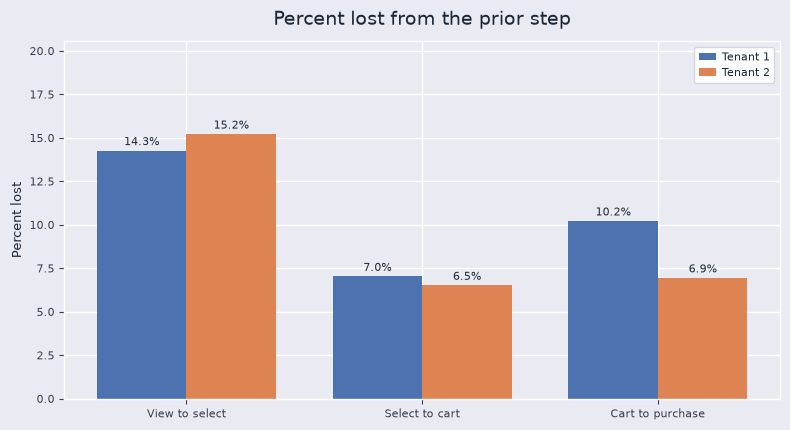

In [8]:
import numpy as np

session_flags = load_session_flags()
steps = [
    ("View to select", "selected", "viewed"),
    ("Select to cart", "carted", "selected"),
    ("Cart to purchase", "purchased", "carted"),
]
tenants = sorted(session_flags["tenant"].unique())
x = np.arange(len(steps))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4.4))
peak = 0
for i, tenant in enumerate(tenants):
    frame = session_flags.loc[session_flags["tenant"] == tenant]
    lost = [100 * (1 - frame[num].sum() / frame[den].sum()) for _, num, den in steps]
    peak = max(peak, max(lost))
    bars = ax.bar(x + (i - 0.5) * width, lost, width, label=tenant_name(tenant), color=f"C{i}")
    for bar, value in zip(bars, lost):
        point(ax, bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.1f}%")
ax.set_xticks(x)
ax.set_xticklabels([name for name, _, _ in steps])
ax.set_ylim(0, peak * 1.35)
polish(ax, "Percent lost from the prior step", ylabel="Percent lost")
ax.legend(loc="upper right", **LEGEND)
fig.tight_layout()
plt.show()


## The basket is the same. The price unit is not.

Left: items in a session that purchased. Right: median price on a purchase row. Right-hand scale is why the discovery revenue sums are not a ranking.


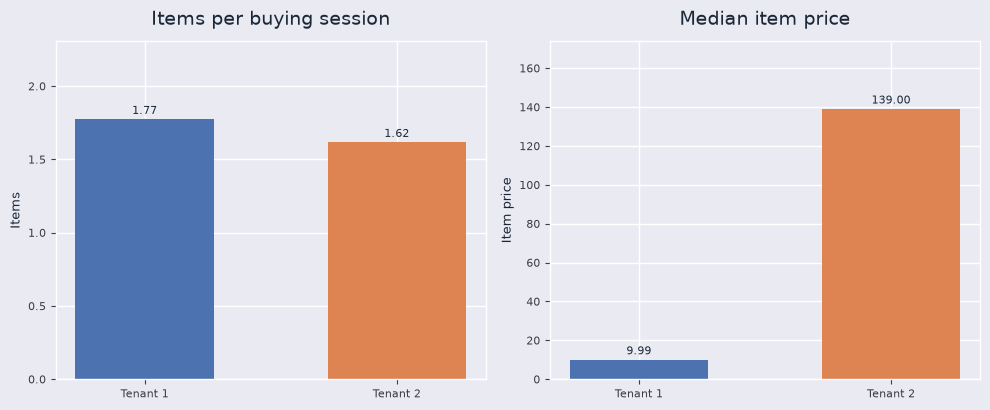

In [9]:
session_flags = load_session_flags()
prices = con.sql("""
SELECT tenant, MEDIAN(item_revenue) AS median_price
FROM events
WHERE event_name = 'purchase' AND item_revenue IS NOT NULL
GROUP BY tenant
ORDER BY tenant
""").df()

items = []
for tenant, frame in session_flags.groupby("tenant", sort=True):
    buyers = frame.loc[frame["purchased"].astype(bool)]
    items.append((tenant, buyers["purchase_rows"].sum() / len(buyers)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
names = [tenant_name(tenant) for tenant, _ in items]
vals = [value for _, value in items]
bars = axes[0].bar(names, vals, color=[f"C{i}" for i in range(len(items))], width=0.55)
for bar, val in zip(bars, vals):
    point(axes[0], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.2f}")
axes[0].set_ylim(0, max(vals) * 1.3)
polish(axes[0], "Items per buying session", ylabel="Items")

price_names = [tenant_name(tenant) for tenant in prices["tenant"]]
price_vals = prices["median_price"].tolist()
bars = axes[1].bar(price_names, price_vals, color=[f"C{i}" for i in range(len(price_vals))], width=0.55)
for bar, val in zip(bars, price_vals):
    point(axes[1], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,.2f}")
axes[1].set_ylim(0, max(price_vals) * 1.25)
polish(axes[1], "Median item price", ylabel="Item price")
fig.tight_layout()
plt.show()


## Inside a tenant, busier days carry that tenant's revenue

Bars are sessions. Line is item revenue for that tenant only. Full width per tenant so the fifteen dates and both labels stay readable. Read each chart on its own revenue axis.


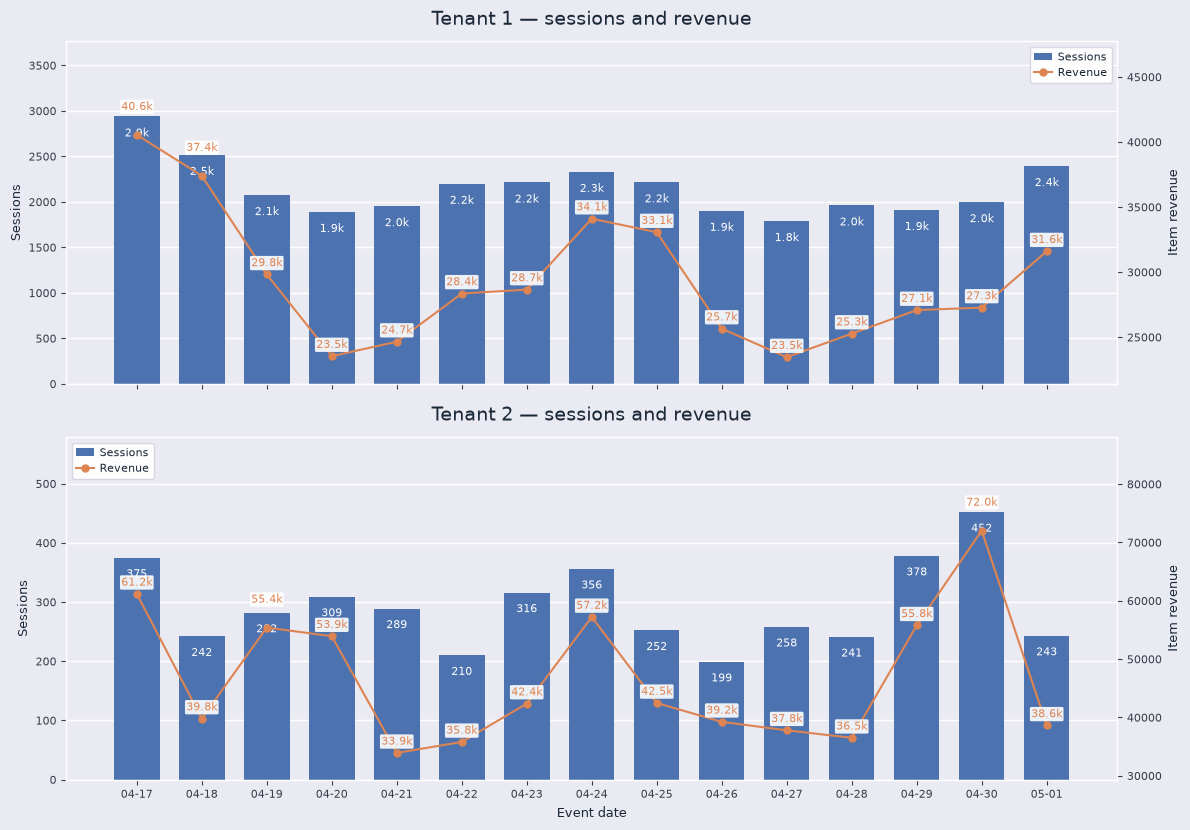

In [10]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
tenants = list(frame.groupby("tenant", sort=True))
fig, axes = plt.subplots(len(tenants), 1, figsize=(12, 4.2 * len(tenants)), sharex=True)
if len(tenants) == 1:
    axes = [axes]

for ax, (tenant, part) in zip(axes, tenants):
    part = part.sort_values("day")
    x = np.arange(len(part))
    ax.bar(x, part["unique_sessions"], width=0.7, color="C0", label="Sessions")
    ax.set_ylim(0, part["unique_sessions"].max() * 1.28)
    rev = ax.twinx()
    rev.set_facecolor("none")
    rev.patch.set_visible(False)
    rev.grid(False)
    rev.plot(x, part["total_item_revenue"], color="C1", marker="o", markersize=5, label="Revenue")
    low = part["total_item_revenue"].min()
    high = part["total_item_revenue"].max()
    span = high - low
    rev.set_ylim(low - span * 0.12, high + span * 0.42)
    fig.canvas.draw()
    for xpos, sessions, revenue in zip(x, part["unique_sessions"], part["total_item_revenue"]):
        session_px = ax.transData.transform((xpos, sessions))[1]
        revenue_px = rev.transData.transform((xpos, revenue))[1]
        point(
            ax,
            xpos,
            sessions,
            short_num(sessions),
            color="white",
            xytext=(0, -8),
            va="top",
        )
        point(
            rev,
            xpos,
            revenue,
            short_num(revenue),
            color="C1",
            xytext=(0, 16 if abs(session_px - revenue_px) < 22 else 4),
            va="bottom",
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9),
        )
    rev.set_ylabel("Item revenue", fontsize=9)
    rev.tick_params(labelsize=8, colors="#3C3C4A")
    rev.yaxis.label.set_color("#1B2838")
    for spine in rev.spines.values():
        spine.set_color("white")
    ax.set_xticks(x)
    ax.set_xticklabels([day.strftime("%m-%d") for day in part["day"]])
    polish(ax, f"{tenant_name(tenant)} — sessions and revenue", ylabel="Sessions", grid="y")
    bars, bar_labels = ax.get_legend_handles_labels()
    lines, line_labels = rev.get_legend_handles_labels()
    peak_x = int(np.argmax(part["unique_sessions"].to_numpy()))
    ax.legend(
        bars + lines,
        bar_labels + line_labels,
        loc="upper left" if peak_x > len(part) / 2 else "upper right",
        **LEGEND,
    )

axes[-1].set_xlabel("Event date", fontsize=9)
fig.tight_layout()
plt.show()


## Stores differ more than the tenants do

Rate = sessions with a purchase / all sessions at the store. Label is that rate plus the kiosk count. Both charts share the percent axis. Tenant 2 only has two stores, so that panel is the short one up top. Extra kiosks are not the higher rate. Same store table as before, sorted by conversion instead of raw revenue.


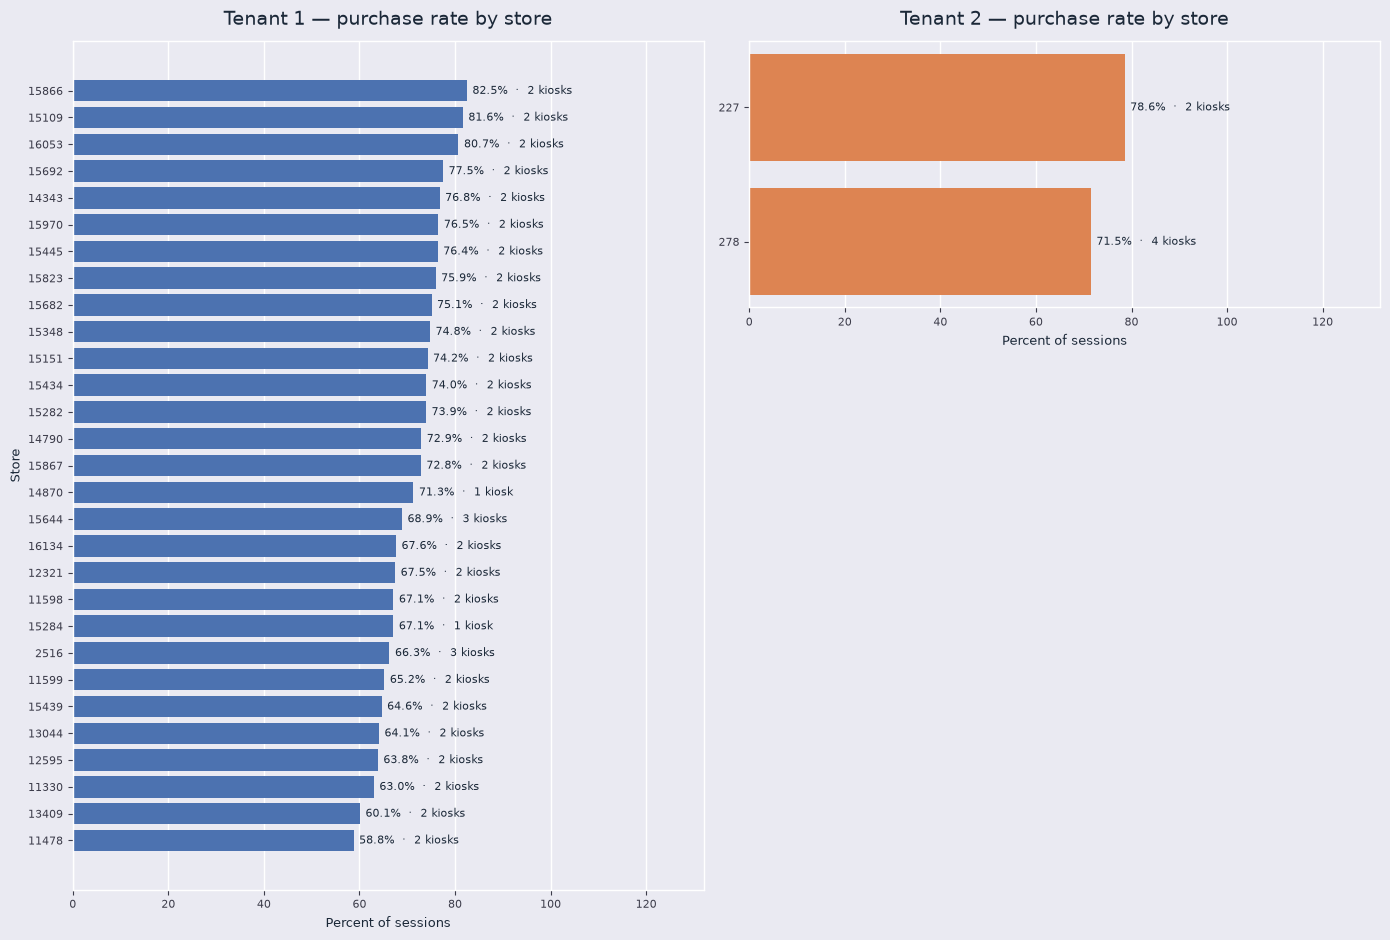

In [11]:
session_flags = load_session_flags()
store = (
    session_flags.groupby(["tenant", "store"], as_index=False)
    .agg(sessions=("session_id", "size"), purchased=("purchased", "sum"), kiosks=("kiosk", "nunique"))
)
store["rate"] = store["purchased"] / store["sessions"]
groups = [
    (tenant, frame.sort_values("rate", ascending=True))
    for tenant, frame in store.groupby("tenant", sort=True)
]
rows = max(len(frame) for _, frame in groups)
fig, axes = plt.subplots(1, len(groups), figsize=(14, 9.5), sharex=True)
if len(groups) == 1:
    axes = [axes]
for ax, (tenant, frame), color in zip(axes, groups, ["C0", "C1"]):
    y = list(range(len(frame)))
    ax.barh(y, frame["rate"] * 100, color=color)
    ax.set_yticks(y)
    ax.set_yticklabels(frame["store"].astype(str))
    for i, (rate, kiosks) in enumerate(zip(frame["rate"], frame["kiosks"])):
        kiosks = int(kiosks)
        noun = "kiosk" if kiosks == 1 else "kiosks"
        point(
            ax,
            rate * 100,
            i,
            f"{rate * 100:.1f}%  ·  {kiosks} {noun}",
            xytext=(4, 0),
            va="center",
            ha="left",
        )
    ax.set_xlim(0, 132)
    polish(
        ax,
        f"{tenant_name(tenant)} — purchase rate by store",
        xlabel="Percent of sessions",
        ylabel="Store" if len(frame) > 5 else None,
        grid="x",
    )
fig.tight_layout()
tall = max(axes, key=lambda ax: len(ax.get_yticks()))
box = tall.get_position()
slot = box.height / rows
for ax, (_, frame) in zip(axes, groups):
    if len(frame) >= rows:
        continue
    pos = ax.get_position()
    height = max(slot * len(frame), 0.28)
    ax.set_position([pos.x0, box.y1 - height, pos.width, height])
plt.show()


## Four prompt areas

Numbers below use the same session grain as the charts. Conversion lives in `data/sql/metric_layer.sql` as `conversion_by_tenant`. Denominator is always all sessions for that tenant (or all sessions at that store / kiosk).

### 1. Conversion

Primary conversion = sessions with at least one purchase ÷ all sessions.

| Tenant | Sessions | Purchased | Purchase conversion |
| --- | ---: | ---: | ---: |
| Tenant 1 | 32,291 | 23,091 | 71.5% |
| Tenant 2 | 4,402 | 3,243 | 73.7% |

Same formula both tenants. Step rates and store rates keep that denominator. Do not swap in view-list sessions as the base.

### 2. Churn

Customer churn is refused. No guest id, and the window is only 15 days.

In-session substitute: carted and never purchased, as a share of sessions that carted.

| Tenant | Reached cart | Cart, no purchase | Cart abandon rate |
| --- | ---: | ---: | ---: |
| Tenant 1 | 25,719 | 2,640 | 10.3% |
| Tenant 2 | 3,485 | 255 | 7.3% |

That is visit abandonment, not a person leaving the brand.

### 3. Segmentation

Session outcomes you can act on:

| Tenant | Browse | Cart, no buy | Purchased |
| --- | ---: | ---: | ---: |
| Tenant 1 | 6,560 (20.3%) | 2,640 (8.2%) | 23,091 (71.5%) |
| Tenant 2 | 904 (20.5%) | 255 (5.8%) | 3,243 (73.7%) |

Browse = never carted and never purchased. Cart-no-buy = carted and never purchased. Purchased = at least one purchase.

Where to act: `store_id` and `kiosk_id`. Example: Tenant 1 store 11478 is at 58.8% purchase conversion (2 kiosks, 764 sessions). RFM and LTV need a guest id. This file does not have one.

### 4. Experiment

One test on the real gap: Tenant 1 cart → purchase (10.2% lost vs 6.9% for Tenant 2).

| Field | Choice |
| --- | --- |
| Hypothesis | A clearer cart / checkout path on Tenant 1 raises cart→purchase retained rate toward Tenant 2 (~93%), without cutting revenue per buying session. |
| Unit | Session |
| Primary metric | Cart→purchase retained rate (purchased ÷ carted) |
| Guardrail | Revenue per buying session, inside Tenant 1 only |
| Sample | ~7,800 Tenant 1 sessions that reached cart (~3,900 per arm) for a ~3 pp lift at 80% power, two-sided 5%. At ~1,700 carted sessions/day on Tenant 1, that is about 5 days of traffic. Round up to 1–2 weeks for day-of-week and store mix. |

No raw-row hypothesis. Event-row counts mix basket size with conversion and do not match the session grain used everywhere else.


In [ ]:
from IPython.display import display

segments = present(con.sql("""
WITH flags AS (
    SELECT
        tenant,
        session_id,
        MAX(event_name = 'add_to_cart') AS carted,
        MAX(event_name = 'purchase') AS purchased
    FROM events
    GROUP BY tenant, session_id
)
SELECT
    tenant,
    COUNT(*) AS sessions,
    COUNT(*) FILTER (WHERE purchased) AS purchased,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchased) / COUNT(*), 1) AS purchase_conversion_pct,
    COUNT(*) FILTER (WHERE NOT carted AND NOT purchased) AS browse,
    ROUND(100.0 * COUNT(*) FILTER (WHERE NOT carted AND NOT purchased) / COUNT(*), 1) AS browse_pct,
    COUNT(*) FILTER (WHERE carted AND NOT purchased) AS cart_no_buy,
    ROUND(100.0 * COUNT(*) FILTER (WHERE carted AND NOT purchased) / COUNT(*), 1) AS cart_no_buy_pct,
    COUNT(*) FILTER (WHERE carted) AS reached_cart,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE carted AND NOT purchased)
        / NULLIF(COUNT(*) FILTER (WHERE carted), 0),
        1
    ) AS cart_abandon_pct
FROM flags
GROUP BY tenant
ORDER BY tenant
""").df())
display(segments)

cart_step = present(con.sql("""
WITH flags AS (
    SELECT
        tenant,
        MAX(event_name = 'add_to_cart') AS carted,
        MAX(event_name = 'purchase') AS purchased
    FROM events
    GROUP BY tenant, session_id
)
SELECT
    tenant,
    COUNT(*) FILTER (WHERE carted) AS carted,
    COUNT(*) FILTER (WHERE purchased) AS purchased,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE purchased)
        / NULLIF(COUNT(*) FILTER (WHERE carted), 0),
        1
    ) AS cart_to_purchase_pct
FROM flags
GROUP BY tenant
ORDER BY tenant
""").df())
display(cart_step)
